<a href="https://colab.research.google.com/github/Yisihaq01/breast-histology-calibration/blob/main/Notebook/04_external_data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from pathlib import Path
import shutil

EXTERNAL_ROOT = Path("/content/external_data")

BACH_ROOT = EXTERNAL_ROOT / "BACH"
BRACS_ROOT = EXTERNAL_ROOT / "BRACS"

for folder in [
    BACH_ROOT / "archives",
    BACH_ROOT / "images",
    BRACS_ROOT / "archives",
    BRACS_ROOT / "images",
    EXTERNAL_ROOT / "metadata",
]:
    folder.mkdir(parents=True, exist_ok=True)

disk = shutil.disk_usage("/content")

print("External data folder:", EXTERNAL_ROOT)
print(f"Free storage: {disk.free / 1024**3:.1f} GB")
print("\nBACH and BRACS folders are ready.")
print("Files in /content are temporary and need saving before runtime deletion.")

External data folder: /content/external_data
Free storage: 87.2 GB

BACH and BRACS folders are ready.
Files in /content are temporary and need saving before runtime deletion.


In [2]:
import hashlib
import requests
from tqdm.auto import tqdm

BACH_URL = (
    "https://zenodo.org/records/3632035/files/"
    "ICIAR2018_BACH_Challenge.zip?download=1"
)

BACH_ARCHIVE = (
    BACH_ROOT / "archives" / "ICIAR2018_BACH_Challenge.zip"
)

EXPECTED_MD5 = "8ae1801334aa943c44627c1eef3631b2"


def file_md5(path):
    digest = hashlib.md5()

    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(8 * 1024 * 1024), b""):
            digest.update(chunk)

    return digest.hexdigest()


if BACH_ARCHIVE.exists():
    print("Archive already exists. Checking it before reuse.")

else:
    partial_path = BACH_ARCHIVE.with_suffix(".zip.part")

    with requests.get(
        BACH_URL,
        stream=True,
        timeout=(30, 180),
    ) as response:

        response.raise_for_status()
        total = int(response.headers.get("Content-Length", 0))

        with partial_path.open("wb") as file, tqdm(
            total=total or None,
            unit="B",
            unit_scale=True,
            desc="Downloading BACH",
        ) as progress:

            for chunk in response.iter_content(
                chunk_size=4 * 1024 * 1024
            ):
                if chunk:
                    file.write(chunk)
                    progress.update(len(chunk))

    actual_md5 = file_md5(partial_path)

    if actual_md5 != EXPECTED_MD5:
        raise RuntimeError(
            f"Checksum mismatch: {actual_md5}. "
            "The partial archive must not be used."
        )

    partial_path.rename(BACH_ARCHIVE)


actual_md5 = file_md5(BACH_ARCHIVE)

assert actual_md5 == EXPECTED_MD5, (
    f"Archive checksum mismatch: {actual_md5}"
)

print("\nPASS: BACH archive checksum verified.")
print("Archive:", BACH_ARCHIVE)
print(f"Size: {BACH_ARCHIVE.stat().st_size / 1024**3:.2f} GiB")


PASS: BACH archive checksum verified.
Archive: /content/external_data/BACH/archives/ICIAR2018_BACH_Challenge.zip
Size: 9.70 GiB


In [3]:
from collections import Counter
from pathlib import PurePosixPath
import zipfile

assert BACH_ARCHIVE.is_file()

with zipfile.ZipFile(BACH_ARCHIVE, "r") as archive:
    archive_files = [
        entry
        for entry in archive.infolist()
        if not entry.is_dir()
    ]

    print("Files in archive:", len(archive_files))

    folder_counts = Counter()
    image_counts = Counter()
    metadata_files = []

    image_extensions = {".tif", ".tiff", ".png", ".jpg", ".jpeg"}
    metadata_extensions = {
        ".csv", ".xlsx", ".xls", ".txt", ".md", ".json"
    }

    for entry in archive_files:
        path = PurePosixPath(entry.filename)

        # Ignore macOS bookkeeping files.
        if "__MACOSX" in path.parts or path.name.startswith("._"):
            continue

        folder = "/".join(path.parts[:2])
        folder_counts[folder] += 1

        if path.suffix.lower() in image_extensions:
            image_counts[str(path.parent)] += 1

        if path.suffix.lower() in metadata_extensions:
            metadata_files.append(entry.filename)

    print("\nTop-level folder counts:")
    for folder, count in sorted(folder_counts.items()):
        print(f"{folder}: {count}")

    print("\nImage counts by folder:")
    for folder, count in sorted(image_counts.items()):
        print(f"{folder}: {count}")

    print("\nPotential metadata/documentation files:")
    if metadata_files:
        for filename in sorted(metadata_files):
            print(filename)
    else:
        print("None found.")

    print("\nFirst 10 image paths:")
    image_paths = [
        entry.filename
        for entry in archive_files
        if PurePosixPath(entry.filename).suffix.lower()
        in image_extensions
        and "__MACOSX" not in PurePosixPath(entry.filename).parts
        and not PurePosixPath(entry.filename).name.startswith("._")
    ]

    for filename in sorted(image_paths)[:10]:
        print(filename)

print("\nPASS: Archive inventory completed. No files extracted.")

Files in archive: 488

Top-level folder counts:
ICIAR2018_BACH_Challenge/Photos: 407
ICIAR2018_BACH_Challenge/WSI: 81

Image counts by folder:
ICIAR2018_BACH_Challenge/Photos/Benign: 100
ICIAR2018_BACH_Challenge/Photos/InSitu: 100
ICIAR2018_BACH_Challenge/Photos/Invasive: 100
ICIAR2018_BACH_Challenge/Photos/Normal: 100
ICIAR2018_BACH_Challenge/WSI/gt_thumbnails: 10
ICIAR2018_BACH_Challenge/WSI/thumbnails: 30

Potential metadata/documentation files:
ICIAR2018_BACH_Challenge/Photos/microscopy_ground_truth.csv

First 10 image paths:
ICIAR2018_BACH_Challenge/Photos/Benign/b001.tif
ICIAR2018_BACH_Challenge/Photos/Benign/b002.tif
ICIAR2018_BACH_Challenge/Photos/Benign/b003.tif
ICIAR2018_BACH_Challenge/Photos/Benign/b004.tif
ICIAR2018_BACH_Challenge/Photos/Benign/b005.tif
ICIAR2018_BACH_Challenge/Photos/Benign/b006.tif
ICIAR2018_BACH_Challenge/Photos/Benign/b007.tif
ICIAR2018_BACH_Challenge/Photos/Benign/b008.tif
ICIAR2018_BACH_Challenge/Photos/Benign/b009.tif
ICIAR2018_BACH_Challenge/Photos/

In [5]:
from pathlib import PurePosixPath
import shutil
import zipfile
import pandas as pd
from tqdm.auto import tqdm
from IPython.display import display

BACH_CLASSES = ("Normal", "Benign", "InSitu", "Invasive")
PHOTOS_PREFIX = ("ICIAR2018_BACH_Challenge", "Photos")

BACH_IMAGES = BACH_ROOT / "images"
BACH_METADATA = BACH_ROOT / "metadata"

BACH_METADATA.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(BACH_ARCHIVE, "r") as archive:
    selected_images = []

    for entry in archive.infolist():
        path = PurePosixPath(entry.filename)

        if (
            not entry.is_dir()
            and path.parts[:2] == PHOTOS_PREFIX
            and len(path.parts) == 4
            and path.parts[2] in BACH_CLASSES
            and path.suffix.lower() in {".tif", ".tiff"}
            and not path.name.startswith("._")
        ):
            selected_images.append(entry)

    assert len(selected_images) == 400
    assert len({entry.filename for entry in selected_images}) == 400

    for entry in tqdm(
        selected_images,
        desc="Extracting microscopy images",
    ):
        path = PurePosixPath(entry.filename)
        destination = BACH_IMAGES / path.parts[2] / path.name
        destination.parent.mkdir(parents=True, exist_ok=True)

        with archive.open(entry) as source:
            with destination.open("wb") as target:
                shutil.copyfileobj(source, target)

    ground_truth_member = (
        "ICIAR2018_BACH_Challenge/Photos/"
        "microscopy_ground_truth.csv"
    )

    ground_truth_path = (
        BACH_METADATA / "microscopy_ground_truth.csv"
    )

    # Preserve the original CSV exactly as supplied.
    with archive.open(ground_truth_member) as source:
        with ground_truth_path.open("wb") as target:
            shutil.copyfileobj(source, target)


print("\nExtracted microscopy images:")

for class_name in BACH_CLASSES:
    count = sum(
        path.suffix.lower() in {".tif", ".tiff"}
        for path in (BACH_IMAGES / class_name).iterdir()
        if path.is_file()
    )

    assert count == 100, (
        f"Unexpected count for {class_name}: {count}"
    )

    print(f"{class_name}: {count}")


# The original CSV has no header row.
ground_truth = pd.read_csv(
    ground_truth_path,
    header=None,
    names=["filename", "original_class"],
    dtype=str,
    keep_default_na=False,
)

for column in ground_truth.columns:
    ground_truth[column] = ground_truth[column].str.strip()

assert len(ground_truth) == 400
assert not ground_truth["filename"].duplicated().any()
assert set(ground_truth["original_class"]) == set(BACH_CLASSES)

# Save a separate copy with descriptive headers.
headered_ground_truth_path = (
    BACH_METADATA / "microscopy_ground_truth_with_headers.csv"
)

ground_truth.to_csv(
    headered_ground_truth_path,
    index=False,
)

print("\nGround-truth CSV with headers:")
print("Shape:", ground_truth.shape)
print("Columns:", ground_truth.columns.tolist())

display(ground_truth.head(10))

print("\nPASS: 400 microscopy images and labels loaded.")
print("Original CSV:", ground_truth_path)
print("CSV with headers:", headered_ground_truth_path)

Extracting microscopy images:   0%|          | 0/400 [00:00<?, ?it/s]


Extracted microscopy images:
Normal: 100
Benign: 100
InSitu: 100
Invasive: 100

Ground-truth CSV with headers:
Shape: (400, 2)
Columns: ['filename', 'original_class']


,filename,original_class
0,n001.tif,Normal
1,n002.tif,Normal
2,n003.tif,Normal
3,n004.tif,Normal
4,n005.tif,Normal
5,n006.tif,Normal
6,n007.tif,Normal
7,n008.tif,Normal
8,n009.tif,Normal
9,n010.tif,Normal



PASS: 400 microscopy images and labels loaded.
Original CSV: /content/external_data/BACH/metadata/microscopy_ground_truth.csv
CSV with headers: /content/external_data/BACH/metadata/microscopy_ground_truth_with_headers.csv


## Verify labels and define the binary evaluation target

We compare the ground-truth CSV against the extracted image
filenames and class folders before creating evaluation metadata.

Binary mapping:
- Normal and Benign: 0 (benign)
- InSitu and Invasive: 1 (malignant)

BACH is reserved for external evaluation. Its original challenge
training set serves as external evaluation data for our
BreakHis-trained model.

Patient identifiers remain unverified. We do not infer patient
identity from image filenames.

In [6]:
# Build an independent inventory from the extracted image folders.
image_records = []

for class_name in BACH_CLASSES:
    for path in sorted((BACH_IMAGES / class_name).iterdir()):
        if (
            path.is_file()
            and path.suffix.lower() in {".tif", ".tiff"}
        ):
            image_records.append({
                "filename": path.name,
                "folder_class": class_name,
                "relative_path": (
                    path.relative_to(BACH_ROOT).as_posix()
                ),
            })

image_inventory = pd.DataFrame(image_records)

assert len(image_inventory) == 400
assert not image_inventory["filename"].duplicated().any()

# Compare every CSV record against the extracted files.
verified_labels = ground_truth.merge(
    image_inventory,
    on="filename",
    how="outer",
    validate="one_to_one",
    indicator=True,
)

assert verified_labels["_merge"].eq("both").all(), (
    "Ground-truth records and extracted images do not match."
)

assert verified_labels["original_class"].eq(
    verified_labels["folder_class"]
).all(), "CSV labels disagree with image-folder labels."

# Prespecified mapping for external binary evaluation.
BACH_LABEL_MAP = {
    "Normal": 0,
    "Benign": 0,
    "InSitu": 1,
    "Invasive": 1,
}

bach_metadata = (
    verified_labels
    .drop(columns=["_merge", "folder_class"])
    .sort_values("filename")
    .reset_index(drop=True)
)

bach_metadata["label"] = (
    bach_metadata["original_class"]
    .map(BACH_LABEL_MAP)
    .astype(int)
)

bach_metadata["dataset"] = "BACH"
bach_metadata["source_subset"] = "challenge_training_microscopy"
bach_metadata["role"] = "external_evaluation_only"

# Leave patient identity unknown until supported by metadata.
bach_metadata["patient_id"] = pd.NA

print("Verified images:", len(bach_metadata))

print("\nOriginal class counts:")
print(
    bach_metadata["original_class"]
    .value_counts()
    .sort_index()
)

print("\nBinary counts (0 = benign, 1 = malignant):")
print(bach_metadata["label"].value_counts().sort_index())

assert bach_metadata["label"].value_counts().to_dict() == {
    0: 200,
    1: 200,
}

display(bach_metadata.head())

print("\nPASS: All CSV labels match the extracted image folders.")
print("Binary mapping verified: 200 benign, 200 malignant.")
print("Patient IDs remain unverified.")

Verified images: 400

Original class counts:
original_class
Benign      100
InSitu      100
Invasive    100
Normal      100
Name: count, dtype: int64

Binary counts (0 = benign, 1 = malignant):
label
0    200
1    200
Name: count, dtype: int64


,filename,original_class,relative_path,label,dataset,source_subset,role,patient_id
0,b001.tif,Benign,images/Benign/b001.tif,0,BACH,challenge_training_microscopy,external_evaluation_only,<NA>
1,b002.tif,Benign,images/Benign/b002.tif,0,BACH,challenge_training_microscopy,external_evaluation_only,<NA>
2,b003.tif,Benign,images/Benign/b003.tif,0,BACH,challenge_training_microscopy,external_evaluation_only,<NA>
3,b004.tif,Benign,images/Benign/b004.tif,0,BACH,challenge_training_microscopy,external_evaluation_only,<NA>
4,b005.tif,Benign,images/Benign/b005.tif,0,BACH,challenge_training_microscopy,external_evaluation_only,<NA>



PASS: All CSV labels match the extracted image folders.
Binary mapping verified: 200 benign, 200 malignant.
Patient IDs remain unverified.


## Audit image integrity, dimensions and duplicates

We decode all 400 microscopy images and record their dimensions,
color modes and frame counts.

We detect exact duplicates using SHA-256 hashes of decoded RGB
pixels, including image dimensions in the hash. We preserve all
original files and review duplicate groups before making any
exclusions.

This audit does not establish whether different images come
from the same patient.

In [7]:
import hashlib
import struct

from PIL import Image
from tqdm.auto import tqdm

audit_records = []
audit_errors = []

for row in tqdm(
    bach_metadata.itertuples(index=False),
    total=len(bach_metadata),
    desc="Auditing BACH images",
):
    image_path = BACH_ROOT / row.relative_path

    try:
        # Check file integrity, then reopen for full decoding.
        with Image.open(image_path) as image:
            image.verify()

        with Image.open(image_path) as image:
            original_mode = image.mode
            image_format = image.format
            frame_count = getattr(image, "n_frames", 1)

            image.seek(0)
            rgb = image.convert("RGB")
            rgb.load()

            width, height = rgb.size

            digest = hashlib.sha256()
            digest.update(struct.pack(">II", width, height))
            digest.update(rgb.tobytes())

        audit_records.append({
            "filename": row.filename,
            "width": width,
            "height": height,
            "original_mode": original_mode,
            "image_format": image_format,
            "frame_count": frame_count,
            "file_bytes": image_path.stat().st_size,
            "rgb_sha256": digest.hexdigest(),
        })

    except Exception as error:
        audit_errors.append({
            "filename": row.filename,
            "error": f"{type(error).__name__}: {error}",
        })


bach_image_audit = pd.DataFrame(audit_records)

print("\nSuccessfully decoded:", len(bach_image_audit))
print("Failed images:", len(audit_errors))

if audit_errors:
    display(pd.DataFrame(audit_errors))

assert not audit_errors, (
    "Image audit failed. Review errors before continuing."
)
assert len(bach_image_audit) == 400
assert bach_image_audit["width"].gt(0).all()
assert bach_image_audit["height"].gt(0).all()

print("\nImage dimensions:")
display(
    bach_image_audit.groupby(["width", "height"])
    .size()
    .reset_index(name="images")
)

print("\nOriginal color modes:")
print(bach_image_audit["original_mode"].value_counts())

print("\nFrame counts:")
print(bach_image_audit["frame_count"].value_counts())

# Attach audit results without changing the original metadata.
bach_audited_metadata = bach_metadata.merge(
    bach_image_audit,
    on="filename",
    how="left",
    validate="one_to_one",
)

duplicate_mask = bach_audited_metadata.duplicated(
    "rgb_sha256",
    keep=False,
)

bach_duplicate_audit = (
    bach_audited_metadata.loc[
        duplicate_mask,
        [
            "rgb_sha256",
            "filename",
            "original_class",
            "label",
            "relative_path",
        ],
    ]
    .sort_values(["rgb_sha256", "filename"])
    .reset_index(drop=True)
)

duplicate_groups = bach_duplicate_audit["rgb_sha256"].nunique()

print("\nUnique decoded RGB images:",
      bach_image_audit["rgb_sha256"].nunique())
print("Exact duplicate groups:", duplicate_groups)
print("Files in duplicate groups:", len(bach_duplicate_audit))

if duplicate_groups:
    display(bach_duplicate_audit)

    print(
        "\nDuplicate groups with conflicting original classes:",
        (
            bach_duplicate_audit.groupby("rgb_sha256")
            ["original_class"].nunique().gt(1).sum()
        ),
    )

    print(
        "Duplicate groups with conflicting binary labels:",
        (
            bach_duplicate_audit.groupby("rgb_sha256")
            ["label"].nunique().gt(1).sum()
        ),
    )

print("\nPASS: Image audit completed. No files removed.")

Auditing BACH images:   0%|          | 0/400 [00:00<?, ?it/s]


Successfully decoded: 400
Failed images: 0

Image dimensions:


,width,height,images
0,2048,1536,400



Original color modes:
original_mode
RGB    400
Name: count, dtype: int64

Frame counts:
frame_count
1    400
Name: count, dtype: int64

Unique decoded RGB images: 400
Exact duplicate groups: 0
Files in duplicate groups: 0

PASS: Image audit completed. No files removed.


## Save the verified BACH metadata

All 400 microscopy images passed decoding and have dimensions
2048 × 1536 pixels. Each image contains one RGB frame.
The decoded-pixel audit found no exact duplicates.

We retain all 400 images for external evaluation and save the
label mapping and audit results. Patient identifiers remain
unverified. Physical-scale normalization and patch extraction
are pending.

In [8]:
import json

BACH_METADATA.mkdir(parents=True, exist_ok=True)

metadata_path = BACH_METADATA / "bach_verified_metadata.csv"
image_audit_path = BACH_METADATA / "bach_image_audit.csv"
duplicate_audit_path = BACH_METADATA / "bach_duplicate_audit.csv"
label_map_path = BACH_METADATA / "bach_binary_label_mapping.json"
summary_path = BACH_METADATA / "bach_audit_summary.json"

# Save small, reproducible metadata files.
bach_audited_metadata.to_csv(metadata_path, index=False)
bach_image_audit.to_csv(image_audit_path, index=False)
bach_duplicate_audit.to_csv(duplicate_audit_path, index=False)

label_mapping = {
    "dataset": "BACH",
    "mapping": BACH_LABEL_MAP,
    "binary_labels": {
        "0": "benign",
        "1": "malignant",
    },
    "role": "external_evaluation_only",
    "note": (
        "Normal tissue is included in the benign binary category. "
        "Original four-class labels are preserved."
    ),
}

audit_summary = {
    "dataset": "BACH",
    "source": "https://zenodo.org/records/3632035",
    "source_subset": "challenge_training_microscopy",
    "archive_md5": EXPECTED_MD5,
    "n_images": int(len(bach_audited_metadata)),
    "class_counts": {
        str(name): int(count)
        for name, count in
        bach_audited_metadata["original_class"].value_counts().items()
    },
    "binary_counts": {
        str(label): int(count)
        for label, count in
        bach_audited_metadata["label"].value_counts().items()
    },
    "dimensions": [
        {
            "width": int(width),
            "height": int(height),
            "images": int(count),
        }
        for (width, height), count in
        bach_image_audit.groupby(["width", "height"]).size().items()
    ],
    "failed_images": int(len(audit_errors)),
    "exact_duplicate_groups": int(duplicate_groups),
    "patient_ids_verified": False,
    "preprocessing_status": "pending",
}

for path, content in [
    (label_map_path, label_mapping),
    (summary_path, audit_summary),
]:
    path.write_text(
        json.dumps(content, indent=2) + "\n",
        encoding="utf-8",
    )

# Reopen saved metadata to verify the export.
saved_metadata = pd.read_csv(
    metadata_path,
    dtype={"filename": str, "patient_id": str},
)

assert len(saved_metadata) == 400
assert saved_metadata["filename"].is_unique
assert saved_metadata["rgb_sha256"].nunique() == 400
assert saved_metadata["patient_id"].isna().all()
assert saved_metadata["label"].value_counts().to_dict() == {
    0: 200,
    1: 200,
}

saved_files = [
    metadata_path,
    image_audit_path,
    duplicate_audit_path,
    label_map_path,
    summary_path,
]

print("Saved audit files:")
for path in saved_files:
    print(f"- {path.name} ({path.stat().st_size:,} bytes)")

# Bundle only the audit files for downloading to your laptop.
audit_bundle = shutil.make_archive(
    str(BACH_ROOT / "bach_audit_outputs"),
    "zip",
    root_dir=BACH_METADATA,
    base_dir=".",
)

print("\nAudit bundle:", audit_bundle)
print("\nPASS: BACH metadata saved and verified.")

Saved audit files:
- bach_verified_metadata.csv (79,737 bytes)
- bach_image_audit.csv (41,864 bytes)
- bach_duplicate_audit.csv (55 bytes)
- bach_binary_label_mapping.json (329 bytes)
- bach_audit_summary.json (574 bytes)

Audit bundle: /content/external_data/BACH/bach_audit_outputs.zip

PASS: BACH metadata saved and verified.


## Verify physical-scale normalization

BACH microscopy images have a documented physical scale of
0.42 µm/pixel. We resample them to the project's frozen target
of 0.50 µm/pixel using LANCZOS interpolation.

We preserve the original images and normalize physical scale
before extracting 224 × 224 patches. No stain normalization
or random augmentation is applied to external evaluation images.

This step checks the resampling behavior on one image per class.

In [9]:
from PIL import Image

BACH_SOURCE_MPP = 0.42
TARGET_MPP = 0.50
PATCH_SIZE = 224


def resample_bach_to_target_mpp(
    image,
    source_mpp=BACH_SOURCE_MPP,
    target_mpp=TARGET_MPP,
):
    image = image.convert("RGB")

    scale = source_mpp / target_mpp

    new_width = round(image.width * scale)
    new_height = round(image.height * scale)

    return image.resize(
        (new_width, new_height),
        Image.Resampling.LANCZOS,
    )


# Select one verified image from each original class.
example_rows = (
    bach_audited_metadata
    .sort_values("filename")
    .groupby("original_class", sort=True)
    .head(1)
)

resampling_records = []

for row in example_rows.itertuples(index=False):
    image_path = BACH_ROOT / row.relative_path

    with Image.open(image_path) as original:
        original_size = original.size
        normalized = resample_bach_to_target_mpp(original)

    expected_size = (
        round(original_size[0] * BACH_SOURCE_MPP / TARGET_MPP),
        round(original_size[1] * BACH_SOURCE_MPP / TARGET_MPP),
    )

    assert normalized.size == expected_size
    assert normalized.mode == "RGB"
    assert min(normalized.size) >= PATCH_SIZE

    resampling_records.append({
        "filename": row.filename,
        "original_class": row.original_class,
        "original_width": original_size[0],
        "original_height": original_size[1],
        "normalized_width": normalized.width,
        "normalized_height": normalized.height,
        "source_mpp": BACH_SOURCE_MPP,
        "target_mpp": TARGET_MPP,
    })

resampling_check = pd.DataFrame(resampling_records)

display(resampling_check)

print("\nResampling factor:", BACH_SOURCE_MPP / TARGET_MPP)
print("Expected normalized size: 1720 × 1290 pixels")
print("\nPASS: Physical-scale normalization verified on all four classes.")
print("Original files remain unchanged. No patches extracted yet.")

,filename,original_class,original_width,original_height,normalized_width,normalized_height,source_mpp,target_mpp
0,b001.tif,Benign,2048,1536,1720,1290,0.42,0.5
1,is001.tif,InSitu,2048,1536,1720,1290,0.42,0.5
2,iv001.tif,Invasive,2048,1536,1720,1290,0.42,0.5
3,n001.tif,Normal,2048,1536,1720,1290,0.42,0.5



Resampling factor: 0.84
Expected normalized size: 1720 × 1290 pixels

PASS: Physical-scale normalization verified on all four classes.
Original files remain unchanged. No patches extracted yet.


## Define the frozen tissue-mask and patch-selection rules

After physical-scale normalization, we generate a deterministic
4 × 4 grid of 224 × 224 pixel patches.

A tissue pixel must satisfy both:
- Mean optical density > 0.08
- HSV saturation > 0.05

We retain patches containing at least 20% tissue, up to 16 per
image. If none qualify, we retain the candidate with the highest
tissue fraction.

These rules match the BreakHis preprocessing. Tissue masking
does not identify tumors. We do not adjust thresholds using BACH.

In [10]:
import numpy as np
from matplotlib.colors import rgb_to_hsv

GRID_SIZE = 4
MAX_PATCHES = 16

OD_THRESHOLD = 0.08
SATURATION_THRESHOLD = 0.05
MIN_PATCH_TISSUE_FRACTION = 0.20


def create_bach_tissue_mask(image):
    rgb = np.asarray(
        image.convert("RGB"),
        dtype=np.float32,
    ) / 255.0

    # Match the original BreakHis implementation.
    rgb = np.clip(rgb, 1 / 255.0, 1.0)

    mean_od = (-np.log(rgb)).mean(axis=2)
    saturation = rgb_to_hsv(rgb)[:, :, 1]

    return (
        (mean_od > OD_THRESHOLD)
        & (saturation > SATURATION_THRESHOLD)
    )


def generate_bach_grid_coordinates(width, height):
    if width < PATCH_SIZE or height < PATCH_SIZE:
        raise ValueError(
            f"Image {width} × {height} is smaller "
            f"than patch size {PATCH_SIZE}."
        )

    x_positions = np.linspace(
        0, width - PATCH_SIZE, GRID_SIZE
    ).round().astype(int)

    y_positions = np.linspace(
        0, height - PATCH_SIZE, GRID_SIZE
    ).round().astype(int)

    return [
        (int(x), int(y))
        for y in y_positions
        for x in x_positions
    ]


def select_bach_patch_coordinates(original_image):
    # Input must be the original image, not an already-resampled image.
    normalized = resample_bach_to_target_mpp(original_image)
    tissue_mask = create_bach_tissue_mask(normalized)

    coordinates = generate_bach_grid_coordinates(
        normalized.width,
        normalized.height,
    )

    candidates = []

    for patch_index, (x, y) in enumerate(coordinates):
        patch_mask = tissue_mask[
            y:y + PATCH_SIZE,
            x:x + PATCH_SIZE,
        ]

        assert patch_mask.shape == (PATCH_SIZE, PATCH_SIZE)

        candidates.append({
            "patch_index": patch_index,
            "x": x,
            "y": y,
            "tissue_fraction": float(patch_mask.mean()),
        })

    selected = [
        candidate
        for candidate in candidates
        if candidate["tissue_fraction"]
        >= MIN_PATCH_TISSUE_FRACTION
    ]

    used_fallback = len(selected) == 0

    if used_fallback:
        selected = [
            max(
                candidates,
                key=lambda item: item["tissue_fraction"],
            )
        ]

    return normalized, selected[:MAX_PATCHES], used_fallback


# Check one original image from each class.
patch_check_records = []

for row in example_rows.itertuples(index=False):
    with Image.open(BACH_ROOT / row.relative_path) as original:
        normalized, selected, used_fallback = (
            select_bach_patch_coordinates(original)
        )

    assert 1 <= len(selected) <= MAX_PATCHES
    assert len({item["patch_index"] for item in selected}) == len(selected)

    for item in selected:
        assert 0 <= item["x"] <= normalized.width - PATCH_SIZE
        assert 0 <= item["y"] <= normalized.height - PATCH_SIZE

    patch_check_records.append({
        "filename": row.filename,
        "original_class": row.original_class,
        "candidate_patches": GRID_SIZE ** 2,
        "retained_patches": len(selected),
        "used_fallback": used_fallback,
        "min_retained_tissue_fraction": min(
            item["tissue_fraction"] for item in selected
        ),
        "max_retained_tissue_fraction": max(
            item["tissue_fraction"] for item in selected
        ),
    })

display(pd.DataFrame(patch_check_records))

print("\nPASS: Patch selection checked on one image per class.")
print("No patch image files saved. No model evaluation performed.")

,filename,original_class,candidate_patches,retained_patches,used_fallback,min_retained_tissue_fraction,max_retained_tissue_fraction
0,b001.tif,Benign,16,16,False,0.917949,1.000000
1,is001.tif,InSitu,16,16,False,0.718072,0.997648
2,iv001.tif,Invasive,16,16,False,0.929508,0.998087
3,n001.tif,Normal,16,12,False,0.233259,1.000000



PASS: Patch selection checked on one image per class.
No patch image files saved. No model evaluation performed.


## Generate the BACH patch manifest

We apply the frozen preprocessing to all 400 original microscopy
images and record retained patch coordinates and tissue fractions.

The manifest references original images. Patch coordinates apply
after resampling to 0.50 µm/pixel. We do not save separate patch
images or run model predictions at this stage.

Each source image remains one evaluation observation. Patches
are inputs to the model, not independent evaluation observations.

In [11]:
bach_patch_records = []
bach_patch_audit_records = []

for row in tqdm(
    bach_audited_metadata.itertuples(index=False),
    total=len(bach_audited_metadata),
    desc="Preparing BACH patch manifest",
):
    with Image.open(BACH_ROOT / row.relative_path) as original:
        normalized, selected, used_fallback = (
            select_bach_patch_coordinates(original)
        )

    for item in selected:
        assert 0 <= item["x"] <= normalized.width - PATCH_SIZE
        assert 0 <= item["y"] <= normalized.height - PATCH_SIZE

        bach_patch_records.append({
            "dataset": "BACH",
            "filename": row.filename,
            "relative_path": row.relative_path,
            "original_class": row.original_class,
            "label": int(row.label),
            "patient_id": row.patient_id,
            "role": row.role,
            "source_mpp": BACH_SOURCE_MPP,
            "target_mpp": TARGET_MPP,
            "normalized_width": normalized.width,
            "normalized_height": normalized.height,
            "patch_size": PATCH_SIZE,
            **item,
            "used_fallback": used_fallback,
        })

    bach_patch_audit_records.append({
        "filename": row.filename,
        "original_class": row.original_class,
        "label": int(row.label),
        "normalized_width": normalized.width,
        "normalized_height": normalized.height,
        "candidate_patches": GRID_SIZE ** 2,
        "retained_patches": len(selected),
        "used_fallback": used_fallback,
    })


bach_patch_manifest = pd.DataFrame(bach_patch_records)
bach_patch_audit = pd.DataFrame(bach_patch_audit_records)

# Verify complete image coverage.
assert len(bach_patch_audit) == 400
assert bach_patch_audit["filename"].is_unique
assert set(bach_patch_manifest["filename"]) == set(
    bach_audited_metadata["filename"]
)

assert not bach_patch_manifest.duplicated(
    ["filename", "patch_index"]
).any()

assert bach_patch_manifest["patch_index"].between(0, 15).all()
assert bach_patch_manifest["tissue_fraction"].between(0, 1).all()
assert bach_patch_audit["retained_patches"].between(1, 16).all()

# Every non-fallback patch must meet the frozen tissue threshold.
non_fallback = ~bach_patch_manifest["used_fallback"]

assert bach_patch_manifest.loc[
    non_fallback, "tissue_fraction"
].ge(MIN_PATCH_TISSUE_FRACTION).all()

# A fallback image must contribute exactly one patch.
fallback_images = bach_patch_audit["used_fallback"]

assert bach_patch_audit.loc[
    fallback_images, "retained_patches"
].eq(1).all()

# Cross-check patch totals against the image-level audit.
counts_from_manifest = (
    bach_patch_manifest.groupby("filename").size().sort_index()
)
counts_from_audit = (
    bach_patch_audit.set_index("filename")
    ["retained_patches"].sort_index()
)

assert counts_from_manifest.equals(counts_from_audit)

print("\nSource images:", len(bach_patch_audit))
print("Retained patches:", len(bach_patch_manifest))
print(
    "Mean patches per image:",
    round(bach_patch_audit["retained_patches"].mean(), 3),
)
print(
    "Images retaining all 16 patches:",
    int(bach_patch_audit["retained_patches"].eq(16).sum()),
)
print(
    "Images requiring fallback:",
    int(bach_patch_audit["used_fallback"].sum()),
)

print("\nRetained patch-count distribution:")
display(
    bach_patch_audit["retained_patches"]
    .value_counts()
    .sort_index()
    .rename_axis("retained_patches")
    .reset_index(name="images")
)

print("\nSummary by original class:")
display(
    bach_patch_audit.groupby("original_class").agg(
        images=("filename", "size"),
        total_patches=("retained_patches", "sum"),
        mean_patches=("retained_patches", "mean"),
        min_patches=("retained_patches", "min"),
        max_patches=("retained_patches", "max"),
        fallback_images=("used_fallback", "sum"),
    )
)

print("\nPASS: All 400 images have verified patch coordinates.")
print("Manifest remains in memory; no model predictions performed.")

Preparing BACH patch manifest:   0%|          | 0/400 [00:00<?, ?it/s]


Source images: 400
Retained patches: 6255
Mean patches per image: 15.638
Images retaining all 16 patches: 342
Images requiring fallback: 0

Retained patch-count distribution:


,retained_patches,images
0,9,1
1,10,5
2,11,1
3,12,9
4,13,8
5,14,9
6,15,25
7,16,342



Summary by original class:


,images,total_patches,mean_patches,min_patches,max_patches,fallback_images
original_class,,,,,,
Benign,100,1584,15.84,12,16,0
InSitu,100,1544,15.44,10,16,0
Invasive,100,1588,15.88,9,16,0
Normal,100,1539,15.39,10,16,0



PASS: All 400 images have verified patch coordinates.
Manifest remains in memory; no model predictions performed.


## Visual verification of patch selection

The full BACH audit retained 6,255 patches from 400 images.
Of these images, 342 (85.5%) retained all 16 candidate patches.
No image required fallback.

We overlay retained patch coordinates on one normalized image
per original class to check placement and alignment. This is a
preprocessing check. The frozen thresholds remain unchanged.

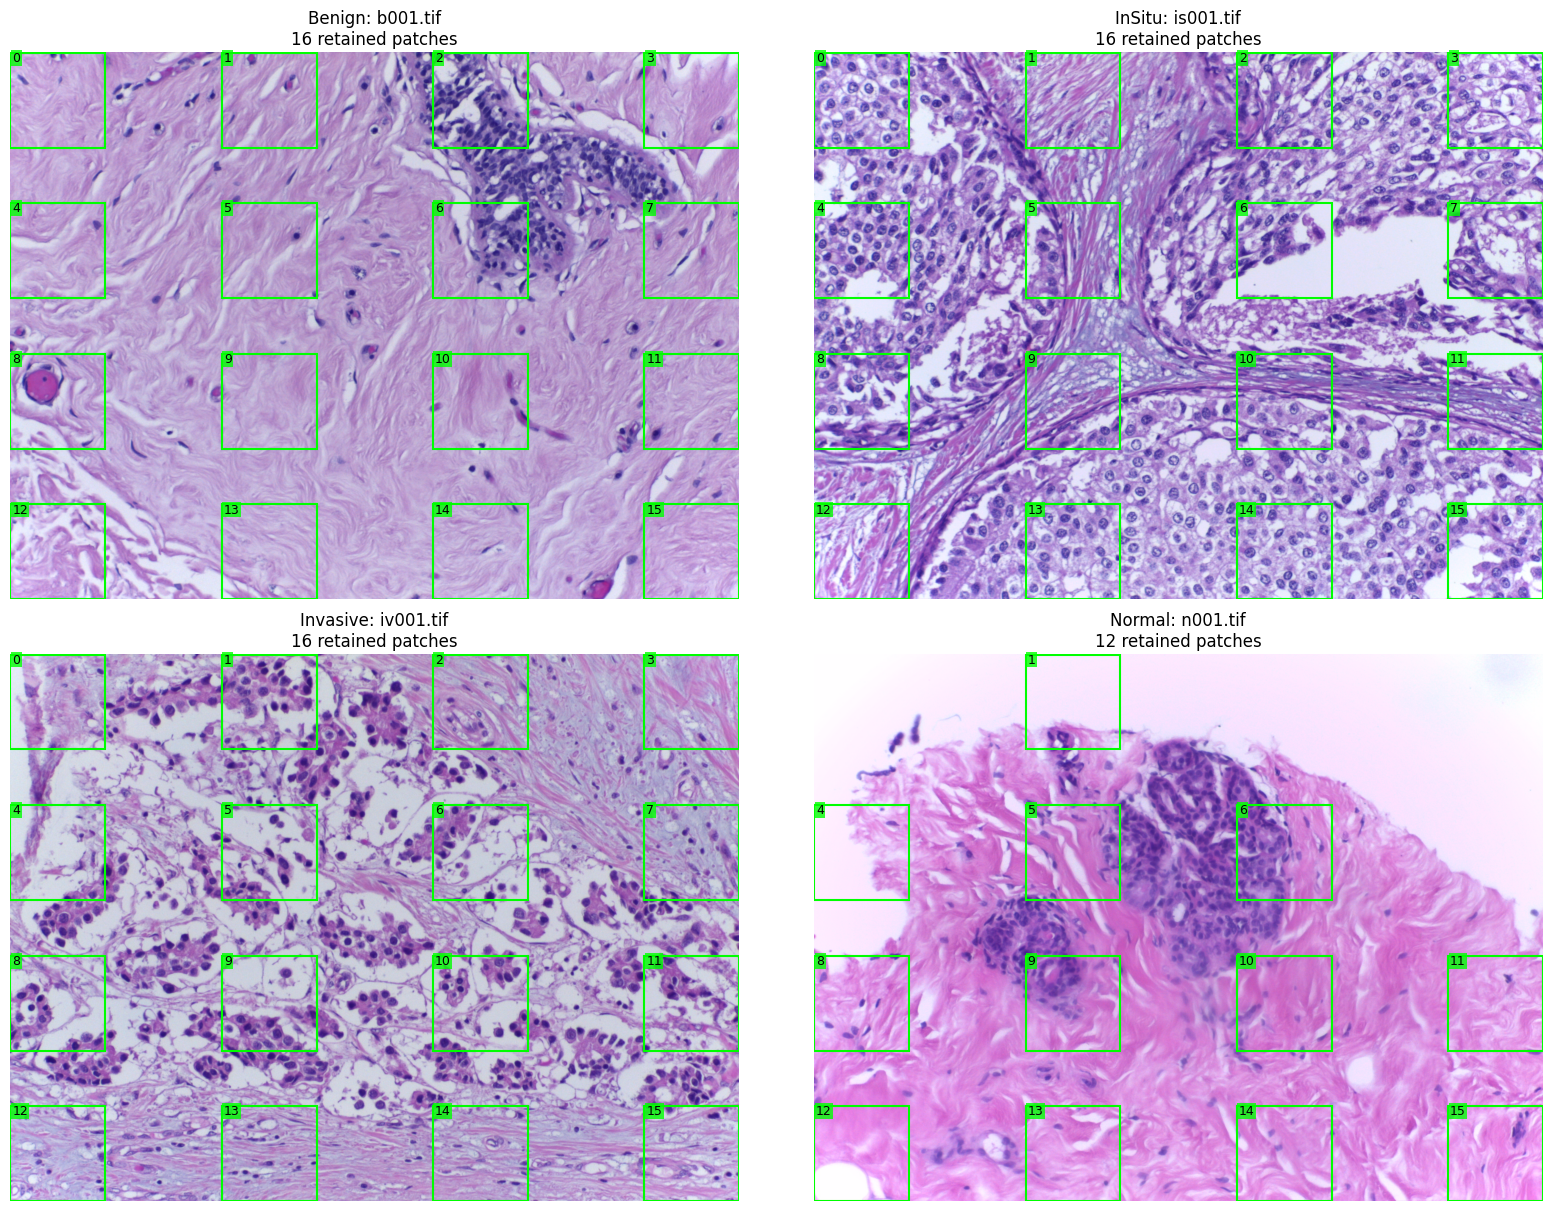

In [13]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 12),
    constrained_layout=True,
)

for ax, row in zip(
    axes.flat,
    example_rows.itertuples(index=False),
):
    with Image.open(BACH_ROOT / row.relative_path) as original:
        normalized = resample_bach_to_target_mpp(original)

    image_patches = bach_patch_manifest.loc[
        bach_patch_manifest["filename"].eq(row.filename)
    ]

    ax.imshow(normalized)

    for patch in image_patches.itertuples(index=False):
        ax.add_patch(
            Rectangle(
                (patch.x, patch.y),
                PATCH_SIZE,
                PATCH_SIZE,
                linewidth=1.5,
                edgecolor="lime",
                facecolor="none",
            )
        )

        ax.text(
            patch.x + 5,
            patch.y + 20,
            str(patch.patch_index),
            color="black",
            fontsize=9,
            bbox={
                "facecolor": "lime",
                "alpha": 0.8,
                "edgecolor": "none",
                "pad": 1,
            },
        )

    ax.set_title(
        f"{row.original_class}: {row.filename}\n"
        f"{len(image_patches)} retained patches"
    )
    ax.axis("off")

plt.show()

## Save the BACH preprocessing artifacts

The frozen preprocessing retained 6,255 patches from 400 images.
Of these images, 342 (85.5%) retained all 16 patches.
No image required fallback.

Visual checks on one image per class showed aligned patch
locations. We preserve the existing thresholds and save the
patch manifest, image-level audit and preprocessing settings.

Coordinates refer to images resampled to 0.50 µm/pixel.
Original images remain unchanged. Patient identifiers remain
unverified, and no model evaluation has been performed.

In [14]:
import json
import shutil
from google.colab import files

patch_manifest_path = BACH_METADATA / "bach_patch_manifest.csv"
patch_audit_path = BACH_METADATA / "bach_patch_audit.csv"
preprocessing_path = BACH_METADATA / "bach_preprocessing_config.json"

bach_patch_manifest.to_csv(patch_manifest_path, index=False)
bach_patch_audit.to_csv(patch_audit_path, index=False)

preprocessing_config = {
    "dataset": "BACH",
    "role": "external_evaluation_only",
    "source_mpp": BACH_SOURCE_MPP,
    "target_mpp": TARGET_MPP,
    "resampling": "LANCZOS",
    "dimension_rounding": "Python round",
    "patch_size": PATCH_SIZE,
    "grid_size": GRID_SIZE,
    "coordinate_generation": "numpy.linspace.round.astype(int)",
    "coordinate_order": "row-major: y outer loop, x inner loop",
    "coordinate_reference": "resampled image",
    "max_patches_per_image": MAX_PATCHES,
    "od_threshold": OD_THRESHOLD,
    "saturation_threshold": SATURATION_THRESHOLD,
    "tissue_rule": "mean_OD > threshold AND HSV_saturation > threshold",
    "minimum_tissue_fraction": MIN_PATCH_TISSUE_FRACTION,
    "fallback": "highest tissue fraction; first candidate breaks ties",
    "stain_normalization": False,
    "evaluation_augmentation": False,
    "n_images": int(len(bach_patch_audit)),
    "n_patches": int(len(bach_patch_manifest)),
    "images_with_16_patches": int(
        bach_patch_audit["retained_patches"].eq(16).sum()
    ),
    "fallback_images": int(
        bach_patch_audit["used_fallback"].sum()
    ),
    "patient_ids_verified": False,
    "model_evaluation_performed": False,
}

preprocessing_path.write_text(
    json.dumps(preprocessing_config, indent=2) + "\n",
    encoding="utf-8",
)

# Reopen the exports and check their contents.
saved_manifest = pd.read_csv(
    patch_manifest_path,
    dtype={"filename": str, "patient_id": str},
)

saved_patch_audit = pd.read_csv(patch_audit_path)

assert len(saved_manifest) == len(bach_patch_manifest) == 6255
assert len(saved_patch_audit) == 400
assert saved_manifest["filename"].nunique() == 400

assert not saved_manifest.duplicated(
    ["filename", "patch_index"]
).any()

assert saved_manifest["patient_id"].isna().all()

saved_counts = (
    saved_manifest.groupby("filename").size().sort_index()
)

audit_counts = (
    saved_patch_audit.set_index("filename")
    ["retained_patches"].sort_index()
)

assert saved_counts.equals(audit_counts)

print("Saved preprocessing files:")
for path in [
    patch_manifest_path,
    patch_audit_path,
    preprocessing_path,
]:
    print(f"- {path.name} ({path.stat().st_size:,} bytes)")

# Bundle all BACH metadata, including the earlier audit files.
preparation_bundle = shutil.make_archive(
    str(BACH_ROOT / "bach_preparation_outputs"),
    "zip",
    root_dir=BACH_METADATA,
    base_dir=".",
)

print("\nPASS: BACH patch manifest and settings saved and verified.")
print("Bundle:", preparation_bundle)

files.download(preparation_bundle)

Saved preprocessing files:
- bach_patch_manifest.csv (823,515 bytes)
- bach_patch_audit.csv (16,513 bytes)
- bach_preprocessing_config.json (881 bytes)

PASS: BACH patch manifest and settings saved and verified.
Bundle: /content/external_data/BACH/bach_preparation_outputs.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>